# Tutorial 1 — The inverse Radon transform of the windows

**The windows of a static scene are its projections along the scan: its
Radon transform, blurred by the line-spread function and sampled.
Tomography inverts such projections. This page builds that inversion step
by step on a well-sampled campaign, checks the result against what the
theory says it must be, and then shows what happens when the campaign is
not well sampled.** The package's three functions are `radon.ramp_filter`,
`radon.direction_weights` and `radon.filtered_backprojection` in `scanlib.radon`.

**What you will see.**

1. A window is one projection of the sky; its Fourier transform is one
   radial slice of the scene's 2-D transform (the projection-slice theorem).
2. Plain back-projection returns every source as a halo; the ramp filter
   removes the halo.
3. Each direction gets its share of the half-turn; the sum over directions is
   a quadrature of the angular integral.
4. On 80 even directions the image equals the scene convolved with the LSF,
   in flux per mas², and the flux around each source integrates back to its
   flux.
5. What the inversion cannot do without: directions that cover the half-turn,
   a scene that holds still, and a signal well above the noise. Three
   pathological cases show the streaks, the smear and the amplified noise.

Conventions: angles in radians, the scan angle ψ counter-clockwise from
north; sky offsets (Δα\*, Δδ) in mas from the primary; the along-scan
coordinate η = Δα\* sin ψ + Δδ cos ψ in mas; fluxes per sample in the
windows' units. Images have rows = Δδ and columns = Δα\*, drawn with east to
the left, in gray with zero at white (negative values, where they occur,
are also white); the primary is marked by a plus and the other sources by
open stars.

| block | task | calls | paper |
|---|---|---|---|
| 1 | a window is one projection of the sky | `joint.scene_positions_al`, `ins.render_window`, `ins.project_al` | Sect. 2.1, Eq. 3; Sect. 3.1, Eq. 9 |
| 2 | the projection-slice theorem, checked on one projection | `ins.project_al` | App. C.2 |
| 3 | plain back-projection, and the ramp filter | `radon.ramp_filter`, `radon.direction_weights`, `radon.filtered_backprojection` | App. C.2, Eq. C.3 |
| 4 | each direction's share of the half-turn | `radon.direction_weights` | App. C.2, Eq. C.3 |
| 5 | the well-sampled inversion against the theory | `radon.filtered_backprojection` | App. C.2; Fig. C.2 |
| 6 | where the premise fails: coverage, motion, noise | `radon.filtered_backprojection`, `sim.simulate_window` | App. C.2; Fig. C.1 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** [The three images and the fit](00_three_images_and_fit.ipynb), then one page per image: this page, [faststack](02_faststack.ipynb), [the triangulation map](03_triangulation_map.ipynb); then where each step's premise breaks, in [`limitations/`](limitations/). The pipeline itself, from the windows to the measurement, is in [`../quickstart/`](../quickstart/).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, the grid and the LSF, flux, σ and S/N, τ and μ, the direction weights, the inverse Radon transform, and the laws (80 even directions, the Gaia forecast).

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# FWHM 100 mas, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                 # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # 59 mas: the distance between the first two sample centers
sigma_lsf = 100.0 / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas] for FWHM 100 mas

In [3]:
# The scene: the primary at the origin, a companion at 250 mas, position angle
# 110 deg, one fifth as bright, and a third source. theta holds the companions
# only, (dra*_1, ddec_1, dra*_2, ddec_2); fluxes primary first.
position_angle = np.deg2rad(110.0)           # of the first companion, from north through east [rad]
theta = np.array([250.0 * np.sin(position_angle), 250.0 * np.cos(position_angle), -200.0, 230.0])
flux = np.array([1000.0, 200.0, 400.0])
# theta.reshape(-1, 2) makes the flat vector one (dra*, ddec) row per companion; the primary's row goes on top
positions = np.vstack([[0.0, 0.0], theta.reshape(-1, 2)])     # (3, 2), primary first

# the 80 even directions over the half-turn [rad]; the offset of 0.01 rad keeps them off the sky axes
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]

In [4]:
# a helper: the windows of the scene at the given scan angles, noise-free or noisy, static or moving
def windows_of(theta, psi, flux=flux, tau=None, sigma_noise=None, rng=None):
    """The windows of a scene at the given scan angles, one per angle, noise-free or noisy.

    Inputs
        theta         the companions' parameters, a flat vector: (dra*, ddec) [mas] per companion for a static
                      scene, (dra*, ddec, mu_a, mu_d) [mas, mas/yr] per companion for a moving one
        psi           the scan angles [rad], one per window
        flux          the fluxes per sample, primary first (default: the scene's three)
        tau           the epochs [yr], one per window, for a moving scene; None: a static scene
        sigma_noise   the noise sigma of one sample; None: noise-free windows
        rng           the random generator of the noise (used only with sigma_noise)
    Returns
        an array of one row per window and one column per sample (18), in flux per sample"""
    # step 1, joint.scene_positions_al projects every source into every window: row j of eta holds the
    # along-scan positions [mas] of all the sources in window j, primary first
    eta = joint.scene_positions_al(theta, psi, tau)

    # step 2, one window per row, in the order of the angles: ins.render_window gives the noise-free samples,
    # sim.simulate_window the same samples plus noise drawn from rng
    windows = []
    for eta_j in eta:
        if sigma_noise is None:
            windows.append(ins.render_window(eta_j, flux, inst))
        else:
            windows.append(sim.simulate_window(eta_j, flux, inst, rng, sigma_noise))
    return np.array(windows)

In [5]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# TRUTH, PRIMARY: two tables of options for ax.scatter (the marker, its size, its colours, its line width, its
# drawing order), one per kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, panel_letter, text=""):
    """Write the panel letter, bold, inside the top-left corner of a panel, and a few words after it.

    Inputs
        ax             the panel (a matplotlib Axes)
        panel_letter   the letter, for example "a"
        text           the words after the letter
    Returns nothing."""
    ax.text(0.04, 0.96, rf"$\bf{{({panel_letter})}}$ " + text, transform=ax.transAxes, va="top", ha="left",
            fontsize=9, bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.8))

In [6]:
# a helper for the figures: one sky image, east to the left, with the scene's sources marked
def show(ax, image, axis, panel_letter, text, marks=None, **imshow_options):
    """Draw one sky image on a panel, east to the left, in gray with zero at white, and mark the sources. The
    primary is a white plus, each other source an open star, so that the image shows inside it.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image, rows ddec and columns dra*
        axis             the coordinates of the image's pixels along either side [mas]
        panel_letter     the panel's letter
        text             the words after the letter
        marks            the (dra*, ddec) [mas] of the sources to mark, one row each, primary first; None: all
                         the sources of the scene
        imshow_options   any other option, handed to ax.imshow (for example vmax)
    Returns
        the drawn image (a matplotlib AxesImage), for a colorbar"""
    if marks is None:
        marks = positions
    extent = (axis[0], axis[-1], axis[0], axis[-1])              # the first and the last coordinate, for both sides
    # the gray scale and its zero, unless the caller gave its own
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    drawn = ax.imshow(image, origin="lower", extent=extent, interpolation="nearest", rasterized=True,
                      **imshow_options)
    # {**TABLE, "key": value}: a copy of the table of options with that one entry replaced
    primary_style = {**PRIMARY, "color": "w"}
    truth_style = {**TRUTH, "facecolor": "none"}
    ax.scatter(marks[0, 0], marks[0, 1], **primary_style)        # row 0 is the primary
    ax.scatter(marks[1:, 0], marks[1:, 1], **truth_style)        # the rows after it: the other sources
    letter(ax, panel_letter, text)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    ax.set_xlabel(EAST)
    return drawn

## 1. A window is one projection of the sky

*Paper: Sect. 2.1, Eq. 3 (the forward model); Sect. 3.1, Eq. 9 (the projection).*

A window taken at scan angle ψ records the scene integrated across the scan
and blurred along it: a source of flux f at sky offset (Δα\*, Δδ) appears as
f · L(g − η) in the sample at g, with η = Δα\* sin ψ + Δδ cos ψ. The
projection of the whole scene is the sum over sources. Nothing across the
scan survives: the window fixes each source along one direction only. The
figure shows the scene and four of its windows.

In [7]:
# the noise-free windows of the scene at four scan angles: four_windows has one row per angle, 18 samples each
four_angles = np.deg2rad([0.0, 45.0, 90.0, 135.0])
four_windows = windows_of(theta, four_angles)

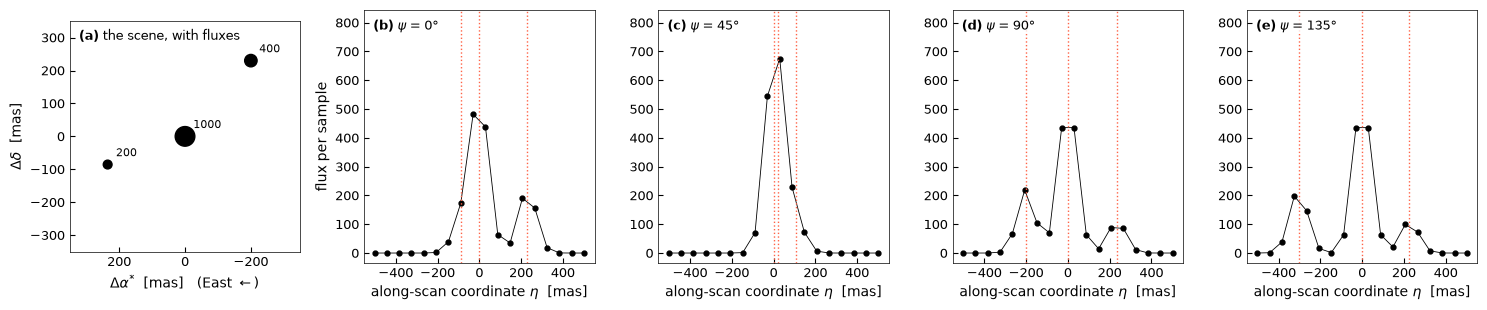

In [8]:
# Figure 1: (a) the scene on the sky, each source a dot with an area in proportion to its flux; (b)-(e) its
# windows at the four scan angles. The dotted lines are the along-scan positions of the three sources
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].scatter(positions[:, 0], positions[:, 1], s=flux / 5, c="k")     # column 0 is dra*, column 1 is ddec
for (dra, ddec), source_flux in zip(positions, flux):
    axes[0].annotate(f"{source_flux:.0f}", (dra, ddec), xytext=(6, 6), textcoords="offset points", fontsize=8)
axes[0].set(xlim=(350, -350), ylim=(-350, 350), xlabel=EAST, ylabel=NORTH, aspect="equal")
letter(axes[0], "a", "the scene, with fluxes")
brightest = four_windows.max()                                           # the largest sample of the four windows
# axes[1:] are the four panels after the scene's, one per scan angle
for ax, panel_letter, psi_j, window in zip(axes[1:], "bcde", four_angles, four_windows):
    ax.plot(grid, window, "o-", color="k", ms=3.5, lw=0.6)
    source_etas = ins.project_al(positions[:, 0], positions[:, 1], psi_j)    # Eq. 9 for the three sources [mas]
    for source_eta in source_etas:
        ax.axvline(source_eta, color=ACCENT, ls=":", lw=1)
    ax.set(xlabel=r"along-scan coordinate $\eta$  [mas]", ylim=(-0.05 * brightest, 1.25 * brightest))
    letter(ax, panel_letter, rf"$\psi$ = {np.degrees(psi_j):.0f}°")
axes[1].set_ylabel("flux per sample")
plt.tight_layout()
plt.show()

## 2. The projection-slice theorem

*Paper: App. C.2 (the projection-slice theorem, in the text before Eq. C.3).*

The continuous projection of point sources blurred by a Gaussian LSF of
width σ is p(t) = Σₖ fₖ G_σ(t − ηₖ). Its Fourier transform along the scan at
frequency κ (cycles per mas) equals the 2-D transform of the blurred scene
on the line through the origin in the scan direction:

$$P_\psi(\kappa) = F(\kappa\sin\psi,\ \kappa\cos\psi),\qquad
F(u,v) = e^{-2\pi^2\sigma^2(u^2+v^2)} \sum_k f_k\, e^{-2\pi i (u\,\Delta\alpha^*_k + v\,\Delta\delta_k)}.$$

So every window measures one radial slice of the Fourier plane, and a set
of windows over the half-turn measures the plane on a star of slices: dense
near the origin, sparse far out. The cell checks the theorem numerically on
one projection.

In [9]:
# one continuous projection at psi = 40 deg, on a fine grid t_grid [mas]: the sum of the three sources' Gaussians
# at their along-scan positions eta_k (positions[:, 0] is the column of dra*, positions[:, 1] that of ddec)
psi0 = np.deg2rad(40.0)
t_grid = np.linspace(-2000.0, 2000.0, 2 ** 14, endpoint=False)      # 16384 points, 4000 mas long
eta_k = ins.project_al(positions[:, 0], positions[:, 1], psi0)
gaussian_norm = np.sqrt(2 * np.pi) * sigma_lsf                      # the normalization of a unit-area Gaussian [mas]
p_t = np.zeros_like(t_grid)                                         # the projection p(t) [flux/mas]
for source_flux, source_eta in zip(flux, eta_k):
    offset = (t_grid - source_eta) / sigma_lsf                      # the distance from the source, in LSF sigmas
    p_t += source_flux * np.exp(-0.5 * offset ** 2) / gaussian_norm

In [10]:
# P: the transform of the projection along the scan. F: the 2-D transform of the blurred scene on the line
# (u, v) = kappa (sin psi0, cos psi0). The mask `band` keeps the frequencies below 0.02 cycles/mas, where the
# transform is not negligible
t_step = t_grid[1] - t_grid[0]                                  # the spacing of the fine grid [mas]
kappa = np.fft.fftfreq(t_grid.size, d=t_step)                   # the frequencies of the FFT [cycles/mas]
# the continuous transform: the FFT's origin is t_grid[0], so restore the phase
P = np.fft.fft(p_t) * t_step * np.exp(-2j * np.pi * kappa * t_grid[0])
u = kappa * np.sin(psi0)                                        # the slice's frequency along dra* [cycles/mas]
v = kappa * np.cos(psi0)                                        # and along ddec
# the sum over the sources of the text's formula: each source's flux times its phase at (u, v)
phase_sum = np.zeros(kappa.size, dtype=complex)
for source_flux, (dra, ddec) in zip(flux, positions):
    phase_sum += source_flux * np.exp(-2j * np.pi * (u * dra + v * ddec))
F = np.exp(-2 * np.pi ** 2 * sigma_lsf ** 2 * (u ** 2 + v ** 2)) * phase_sum
band = np.abs(kappa) < 0.02
worst_difference = np.abs(P[band] - F[band]).max() / np.abs(F).max()
print(f"max |P - F| / max |F| on |kappa| < 0.02 cycles/mas: "
      f"{worst_difference:.1e}")

max |P - F| / max |F| on |kappa| < 0.02 cycles/mas: 3.1e-15


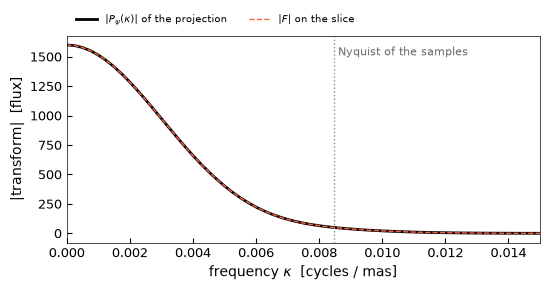

In [11]:
# Figure 2: the two transforms against frequency; one scan is one slice of the Fourier plane
fig, ax = plt.subplots(figsize=(5.6, 3.0))
order = np.argsort(kappa)                               # the FFT's frequencies in increasing order, for the line
ax.plot(kappa[order], np.abs(P[order]), color="k", lw=2, label=r"$|P_\psi(\kappa)|$ of the projection")
ax.plot(kappa[order], np.abs(F[order]), color=ACCENT, ls="--", lw=1, label=r"$|F|$ on the slice")
nyquist = 0.5 / pitch                                   # the samples' Nyquist frequency [cycles/mas]
ax.axvline(nyquist, color="0.55", ls=":", lw=1)
axis_top = ax.get_ylim()[1]                             # get_ylim returns (bottom, top); [1] keeps the top
ax.text(nyquist, axis_top * 0.9, " Nyquist of the samples", color="0.4", fontsize=8)
ax.set(xlim=(0, 0.015), xlabel=r"frequency $\kappa$  [cycles / mas]", ylabel="|transform|  [flux]")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

## 3. Plain back-projection, and the ramp filter

*Paper: App. C.2, Eq. C.3 (the filtered backprojection, with the ramp-filtered scan q).*

**Plain back-projection** lays every window back along its own lines (each
pixel takes the window's value at its own η) and sums over the directions.
It is not the inverse: the star of slices weights the Fourier plane by 1/|κ|,
so every source returns as a halo falling off as 1/r. **The ramp filter**
multiplies each window's spectrum by |κ| first, which cancels that
weighting. The first figure shows one window as a density (flux per mas)
and the same window after the ramp filter: each source now has a negative
lobe on either side, and those lobes are what cancel the halo when the
filtered windows of all directions are summed (second figure).

`radon.ramp_filter` does three things worth knowing. It divides the samples by
the pitch, so the projection is a density in flux per mas. It zero-pads the
spectrum to 16 window lengths, so the filtered projection is evaluated on a
grid 8 times finer than the samples by band-limited (sinc) interpolation,
never by drawing straight lines between samples: the window is undersampled
at the LSF scale (Nyquist at 1/118 cycles per mas against an LSF that
extends to about 1/100), and linear interpolation would add its own
spectrum. And with the frequency step Δκ = 1/(16 N p) and numpy's 1/n in
the inverse transform, the Riemann sum of the inversion reduces to
`8 * irfft(rfft(density) * |κ|)` with no other factor, so the result is
already in flux per mas².

In [12]:
# one window (windows_of returns one row per angle; [0] takes the only row) and the same window after the ramp
# filter: radon.ramp_filter returns the fine grid t_fine [mas] and the filtered projection q [flux/mas^2] on it
window_at_psi0 = windows_of(theta, [psi0])[0]
t_fine, q = radon.ramp_filter(window_at_psi0, grid)

In [13]:
# the sky grid (half-size 400 mas, 4 mas pixels), the windows on the 80 even directions, and each
# direction's weight [rad]
half = 400.0                                 # the half-size of the sky grid [mas]
step = 4.0                                   # its pixel [mas]
axis = np.arange(-half, half + 1e-9, step)   # the pixels' coordinates along either side; 1e-9 keeps the last one
# sky_dra, sky_ddec: the dra* and the ddec of every pixel [mas]; rows are ddec, columns dra*
sky_dra, sky_ddec = np.meshgrid(axis, axis)
even_windows = windows_of(theta, EVEN)
weights = radon.direction_weights(EVEN)

In [14]:
# plain back-projection, written out: no filter
plain = np.zeros_like(sky_dra)
for psi_j, weight_j, window_j in zip(EVEN, weights, even_windows):
    eta_of_pixels = sky_dra * np.sin(psi_j) + sky_ddec * np.cos(psi_j)   # Eq. 9: every pixel's along-scan coordinate
    density = window_j / pitch                                           # the window as flux per mas
    # each window's density laid back along its own line, weighted by its share; np.interp reads the density
    # at each pixel's eta, and gives zero outside the window
    plain += weight_j * np.interp(eta_of_pixels, grid, density, left=0.0, right=0.0)

In [15]:
# filtered back-projection, the package's call. It returns the image [flux/mas^2] and its axis; `_` drops the
# axis, which equals `axis` above
filtered, _ = radon.filtered_backprojection(EVEN, even_windows, inst, half, step)

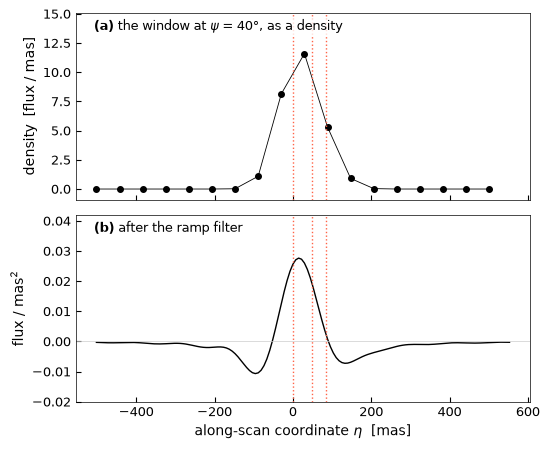

In [16]:
# Figure 3: the window at 40 deg as a density, and after the ramp filter; dotted lines: the three sources
fig, axes = plt.subplots(2, 1, figsize=(5.6, 4.6), sharex=True)
density = window_at_psi0 / pitch                                 # the window as flux per mas
axes[0].plot(grid, density, "o-", color="k", ms=4, lw=0.6)
axes[0].set(ylabel="density  [flux / mas]",
            ylim=(-0.08 * window_at_psi0.max() / pitch, 1.3 * window_at_psi0.max() / pitch))
letter(axes[0], "a", rf"the window at $\psi$ = {np.degrees(psi0):.0f}°, as a density")
axes[1].plot(t_fine, q, color="k", lw=1)
axes[1].axhline(0, color="0.8", lw=0.5)
axes[1].set(xlabel=r"along-scan coordinate $\eta$  [mas]", ylabel=r"flux / mas$^2$", ylim=(-0.02, 0.042))
letter(axes[1], "b", "after the ramp filter")
source_etas = ins.project_al(positions[:, 0], positions[:, 1], psi0)     # Eq. 9 for the three sources [mas]
for ax in axes:
    for source_eta in source_etas:
        ax.axvline(source_eta, color=ACCENT, ls=":", lw=1)
plt.tight_layout()
plt.show()

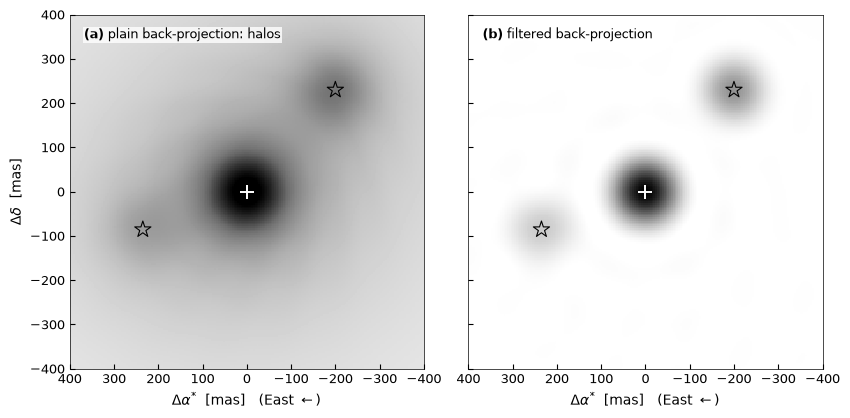

In [17]:
# Figure 4: the two back-projections of the scene on the 80 even directions
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.4), sharey=True)
show(axes[0], plain, axis, "a", "plain back-projection: halos")
show(axes[1], filtered, axis, "b", "filtered back-projection")
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 4. Each direction's share of the half-turn

*Paper: App. C.2, Eq. C.3 (the angular weight of each scan).*

A scan direction is defined modulo π: a window at ψ and one at ψ + π
measure the same line, read backwards. `radon.direction_weights` reduces the
angles to [0, π), sorts them, and gives each direction half the gap to each
neighbor, so the weights sum to π (π/J each for an even pattern). With
those weights the sum over windows is a quadrature of the angular integral
of the inversion rather than a vote: a direction scanned twice does not
count twice, and a direction standing alone in a wide gap carries that
gap's share. The figure compares the even set with the first 40 scan angles
of the public Gaia forecast for the Pleiades (stored with the reference
cases): the forecast scans along a few bundles of directions and leaves
most of the half-turn to a handful of windows.

In [18]:
# the 40 scan angles of the Gaia forecast [rad], stored with the reference cases
ref = np.load("../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]

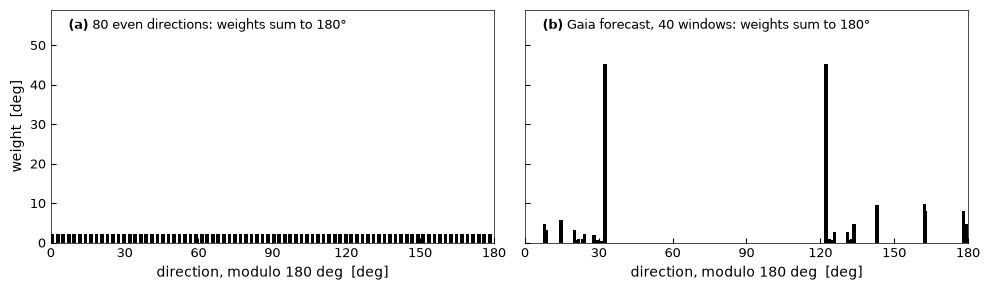

In [19]:
# Figure 5: the weight of each direction, for the even set and for the forecast. The horizontal axis is the
# direction modulo 180 deg, not the scan angle over the turn: the subject is the coverage of the half-turn
fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), sharey=True)
# one row per panel: the panel, its letter, its set of scan angles [rad], its name
panels = ((axes[0], "a", EVEN, "80 even directions"),
          (axes[1], "b", GAIA, "Gaia forecast, 40 windows"))
for ax, panel_letter, psi_set, name in panels:
    set_weights = radon.direction_weights(psi_set)               # each direction's share of the half-turn [rad]
    direction = np.degrees(np.mod(psi_set, np.pi))               # the scan angle modulo 180 deg [deg]
    ax.bar(direction, np.degrees(set_weights), width=1.5, color="k")
    ax.set(xlim=(0, 180), xticks=np.arange(0, 181, 30), xlabel="direction, modulo 180 deg  [deg]")
    letter(ax, panel_letter, f"{name}: weights sum to {np.degrees(set_weights.sum()):.0f}°")
# after the loop set_weights is the forecast's
axes[1].set_ylim(0, 1.3 * np.degrees(set_weights.max()))         # room for the words above the forecast's tallest bar
axes[0].set_ylabel("weight  [deg]")
plt.tight_layout()
plt.show()

## 5. The well-sampled inversion against the theory

*Paper: App. C.2; Fig. C.2 compares the inversion with the same target, the scene convolved with the LSF.*

What must the image be? The exact inverse Radon transform of projections
blurred along the scan by a 1-D Gaussian of width σ is the scene convolved
with the 2-D kernel whose every projection is that Gaussian: the isotropic
2-D Gaussian of the same σ. So on directions that cover the half-turn the
image should equal

$$I(\Delta\alpha^*, \Delta\delta) = \sum_k \frac{f_k}{2\pi\sigma^2}\,
\exp\!\left(-\frac{(\Delta\alpha^*-\Delta\alpha^*_k)^2 + (\Delta\delta-\Delta\delta_k)^2}{2\sigma^2}\right)$$

in flux per mas², and the image integrated over a disc around an isolated
source should return the fraction of the source's flux the Gaussian holds
within that disc (98 % within 120 mas). The cells build the image up over
3, 10 and 80 directions, then compare the 80-direction image with the
formula and integrate the flux.

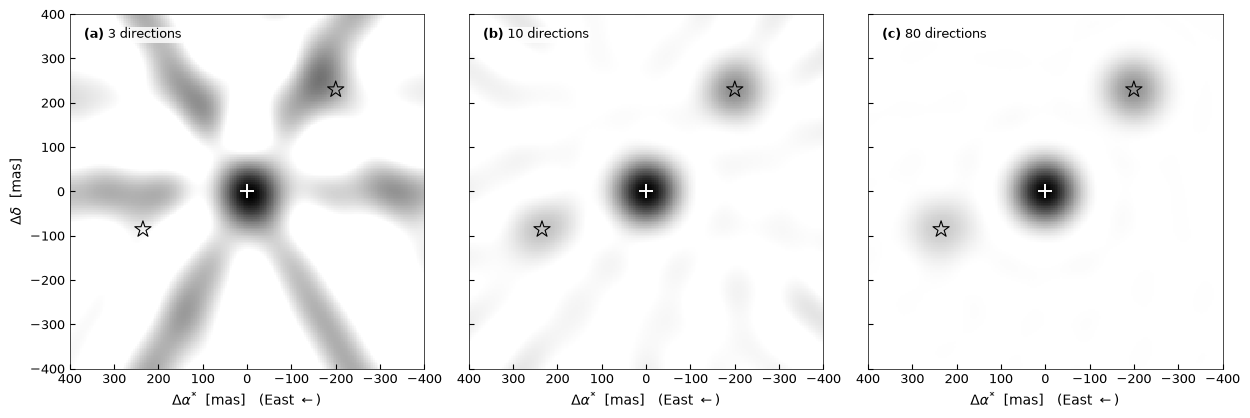

In [20]:
# Figure 6: the image built up over more and more directions: streaks give way to the blurred scene. The call
# returns the image and its axis; `_` drops the axis, which equals `axis` above
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4), sharey=True)
for ax, panel_letter, n_directions in zip(axes, "abc", (3, 10, 80)):
    psi_set = np.linspace(0.0, np.pi, n_directions, endpoint=False) + 0.01   # even directions, as EVEN [rad]
    set_windows = windows_of(theta, psi_set)
    image, _ = radon.filtered_backprojection(psi_set, set_windows, inst, half, step)
    show(ax, image, axis, panel_letter, f"{n_directions} directions")
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

In [21]:
# the 80-direction image against the formula: the scene convolved with the 2-D Gaussian of the LSF's width,
# on the same grid; their peaks, their rms difference, and the total flux (the sum times the pixel's area)
blurred = np.zeros_like(sky_dra)                                 # the formula of the text [flux/mas^2]
for source_flux, (dra, ddec) in zip(flux, positions):
    distance_squared = (sky_dra - dra) ** 2 + (sky_ddec - ddec) ** 2     # of every pixel from the source [mas^2]
    blurred += source_flux / (2 * np.pi * sigma_lsf ** 2) * np.exp(-0.5 * distance_squared / sigma_lsf ** 2)
rms_difference = np.sqrt(np.mean((filtered - blurred) ** 2))
pixel_area = step ** 2                                           # [mas^2]
print(f"peak of the image {filtered.max():.4f} flux/mas², of the formula {blurred.max():.4f}; "
      f"rms difference {rms_difference:.1e} "
      f"({100 * rms_difference / blurred.max():.2f} % of the peak)")
print(f"total flux: image {np.sum(filtered) * pixel_area:.1f}, scene {flux.sum():.1f}")

peak of the image 0.0765 flux/mas², of the formula 0.0883; rms difference 9.3e-04 (1.05 % of the peak)
total flux: image 1599.4, scene 1600.0


In [22]:
# the flux within 120 mas of each source: the image's, and the formula's. The mask `disc` keeps the pixels of
# that disc
r_disc = 120.0                                               # the disc's radius [mas]
held = 1.0 - np.exp(-0.5 * (r_disc / sigma_lsf) ** 2)       # the fraction of a Gaussian within r_disc
for source_flux, (dra, ddec) in zip(flux, positions):
    disc = np.hypot(sky_dra - dra, sky_ddec - ddec) < r_disc
    flux_in_disc = np.sum(filtered[disc]) * step ** 2        # the image's sum over the disc times the pixel's area
    print(f"source at ({dra:6.1f}, {ddec:6.1f}): flux {source_flux:6.1f}; within {r_disc:.0f} mas the image holds "
          f"{flux_in_disc:6.1f}, the formula {held * source_flux:6.1f}")

source at (   0.0,    0.0): flux 1000.0; within 120 mas the image holds  998.0, the formula  981.5
source at ( 234.9,  -85.5): flux  200.0; within 120 mas the image holds  197.4, the formula  196.3
source at (-200.0,  230.0): flux  400.0; within 120 mas the image holds  392.6, the formula  392.6


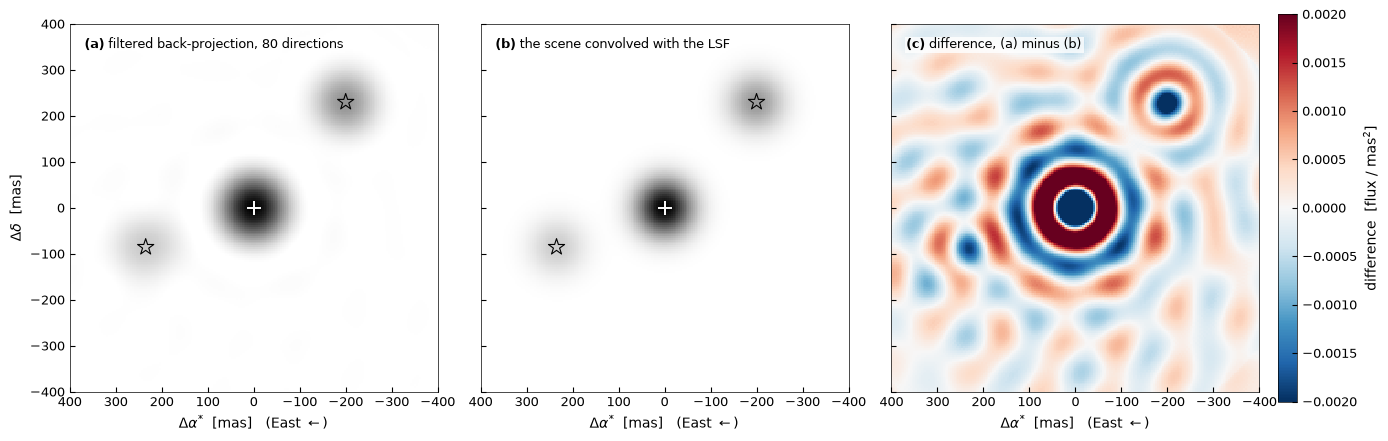

In [23]:
# Figure 7: the image, the formula, and their difference
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.4), sharey=True)
show(axes[0], filtered, axis, "a", "filtered back-projection, 80 directions")
show(axes[1], blurred, axis, "b", "the scene convolved with the LSF")
# the difference is signed: the one place for a two-colour scale, symmetric about zero, with a colorbar
extent = (axis[0], axis[-1], axis[0], axis[-1])                  # the first and the last coordinate, for both sides
difference_drawn = axes[2].imshow(filtered - blurred, origin="lower", extent=extent, cmap="RdBu_r",
                                  vmin=-0.002, vmax=0.002, interpolation="nearest", rasterized=True)
letter(axes[2], "c", "difference, (a) minus (b)")
axes[2].set_aspect("equal")
axes[2].set_xlim(axis[-1], axis[0])                              # east to the left
axes[2].set_xlabel(EAST)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
fig.colorbar(difference_drawn, ax=axes, label=r"difference  [flux / mas$^2$]", fraction=0.02, pad=0.015)
plt.show()

The flux integrates back for every source and in total, and the image
follows the formula to about a percent of its peak, rms. The peak itself is
lower than the formula's: the windows are sampled, and the part of the LSF's
spectrum beyond the samples' Nyquist frequency (about 8 % of a source's
peak) is lost. The image is the band-limited blurred scene; the flux, which
sits at zero frequency, is conserved. The faint residual pattern is the
finite set of directions: 80 slices are not a continuum.

Three more things to keep in mind when reading such an image.

- **Units.** The image is a surface brightness, flux per mas², not the
  windows' flux per sample; its peak for a source of flux f is
  f / (2πσ²).
- **The window's edge.** A source outside every window contributes nothing
  and leaves a hole; one near the edge is clipped in the windows whose scan
  runs along it, and its image is distorted. Keep the scene well inside the
  window (here ±500 mas).
- **Nothing is measured on it.** The image is a picture at the LSF's
  resolution; positions, fluxes and motions come from the forward fit of all
  windows (`scanlib.joint`), which needs none of the premises below.

## 6. Where the premise fails

*Paper: App. C.2; Fig. C.1 shows the streaks on the Gaia forecast. The drifting scene and the low S/N are not in the paper; they are here because the inversion assumes a static scene and a clean signal.*

The inversion rests on three things the data may not give it. Each panel
below breaks one.

**Directions that cover the half-turn.** A range of directions never
scanned is a wedge of the Fourier plane never measured. The image of a
point source, the inversion's *beam*, grows streaks along the scanned
directions, and the streaks of the primary run across the companions. The
measure is the beam's largest excursion, positive or negative, farther than
1.5 FWHM from the source, relative to its peak.

**A scene that holds still.** The transform is of *one* scene. A companion
that drifts across the campaign is somewhere else in every window, and the
inversion spreads it along its track. The drift here is 30 mas/yr over 4.6
years, about 140 mas, more than a FWHM.

**A signal well above the noise.** The ramp filter multiplies the spectrum
by |κ|: it amplifies the high frequencies, where the noise lives and the
signal does not. At a signal-to-noise ratio of 100 per window (the primary's
total flux over the noise per sample) the image is clean; at 10 the noise
dominates it, though the forward fit still measures the companion at that
level.

In [24]:
# the beam: the image of one point source of flux 1000 at the origin, on each set of directions. The mask `far`
# keeps the pixels farther than 1.5 FWHM from the source; [0.0] and [1000.0] are the one position and flux
point = np.array([[0.0, 0.0]])
far = np.hypot(sky_dra, sky_ddec) > 1.5 * 100.0
for name, psi_set in (("80 even directions", EVEN), ("Gaia forecast", GAIA)):
    # a source at the origin is at eta = 0 at every scan angle: the same noise-free window, once per angle
    point_windows = []
    for _ in psi_set:
        point_windows.append(ins.render_window([0.0], [1000.0], inst))
    point_windows = np.array(point_windows)
    beam, _ = radon.filtered_backprojection(psi_set, point_windows, inst, half, step)   # `_` drops the axis
    far_excursion = np.abs(beam[far]).max() / beam.max()
    print(f"beam, {name:20s}: largest far excursion {far_excursion:.3f} of the peak")

beam, 80 even directions  : largest far excursion 0.011 of the peak
beam, Gaia forecast       : largest far excursion 0.290 of the peak


In [25]:
# the epochs of the drifting case, the drifting companion's parameters (dra*, ddec, mu_a, mu_d), and the
# random generator of the noisy case
tau = np.linspace(-2.3, 2.3, EVEN.size)                      # epochs [yr]
theta_moving = np.array([theta[0], theta[1], 25.0, -16.6])   # the pair's companion drifting 30 mas/yr
# the seed is one number, 11: a label only (why 11: not stated). The generator's draws are the noise of the
# 80 windows of the S/N 10 case, in the order of the directions
rng_noise = np.random.default_rng(11)

In [26]:
# the three images; [0] keeps the image of each call and drops its axis. flux[:2] keeps the primary and the
# first companion: the drifting scene is the pair alone
forecast_windows = windows_of(theta, GAIA)
forecast_image = radon.filtered_backprojection(GAIA, forecast_windows, inst, half, step)[0]
pair_flux = flux[:2]
drifting_windows = windows_of(theta_moving, EVEN, pair_flux, tau)
drifting_image = radon.filtered_backprojection(EVEN, drifting_windows, inst, half, step)[0]
# a noise sigma of 100 per sample is S/N 10 for the primary's flux of 1000
noisy_windows = windows_of(theta, EVEN, sigma_noise=100.0, rng=rng_noise)
noisy_image = radon.filtered_backprojection(EVEN, noisy_windows, inst, half, step)[0]
# cases: one (title, image) pair per panel of Figure 8
cases = (
    ("Gaia forecast: streaks", forecast_image),
    ("companion drifting 30 mas/yr", drifting_image),
    ("S/N 10", noisy_image),
)

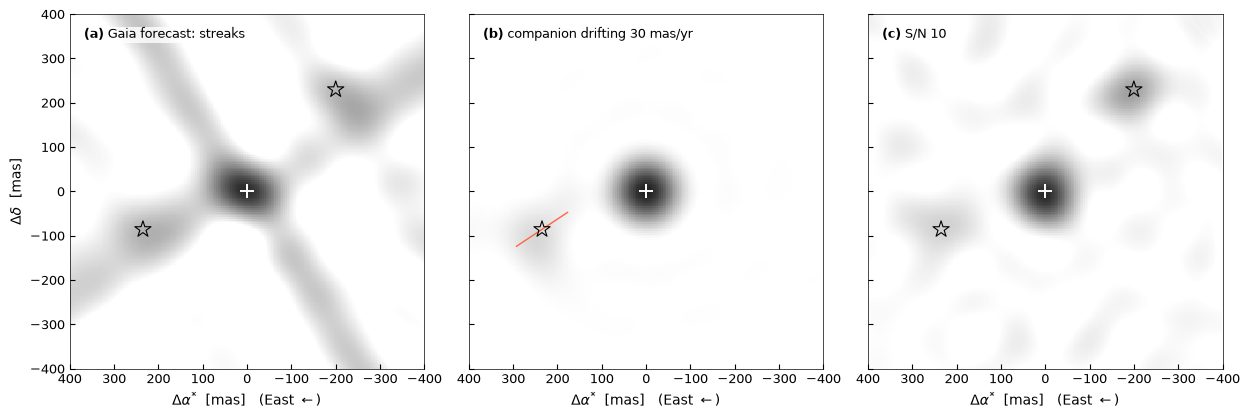

In [27]:
# Figure 8: the three cases on the gray scale of the well-sampled image. In (b) the line is the companion's
# track: theta_moving[:2] is its position at the reference epoch, theta_moving[2:] its proper motion
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4), sharey=True)
for ax, panel_letter, (title, image) in zip(axes, "abc", cases):
    # the drifting scene (b) is the pair alone: positions[:2] keeps the primary and the first companion, whose
    # star is its position at the reference epoch
    if panel_letter == "b":
        marks = positions[:2]
    else:
        marks = None                                     # None: show marks all the sources of the scene
    show(ax, image, axis, panel_letter, title, marks=marks, vmax=blurred.max())
# the drifting companion: its track over the campaign, one row for the first epoch and one for the last.
# np.outer makes each epoch times the proper motion: the displacement at that epoch
first_and_last = [tau.min(), tau.max()]
track = theta_moving[:2] + np.outer(first_and_last, theta_moving[2:])
axes[1].plot(track[:, 0], track[:, 1], color=ACCENT, lw=1)       # column 0 is dra*, column 1 is ddec
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## What this establishes

*Paper: App. C.2.*

- A window is one radial slice of the scene's Fourier plane. The ramp
  filter undoes the 1/|κ| weighting of the star of slices, and the
  back-projection with each direction's share of the half-turn is a
  quadrature of the inversion.
- On directions that cover the half-turn, a scene that holds still and a
  clean signal, the image is the scene convolved with the LSF, in flux per
  mas², and the flux integrates back.
- Clumped directions leave streaks, a drifting companion is spread along its
  track, and the ramp amplifies the noise. None is a flaw of the estimator:
  the premise fails. The image stays a picture; the measurement is the
  forward fit of all windows (`scanlib.joint`, tutorial 0), which needs
  none of the three.
- Tutorial 2 shows faststack, a stack of the samples that avoids the
  streaks and the halo, with its own limits.